# 0. Start here: how much quantum computer does one energy cost?

You have a Hamiltonian and want its ground-state energy to a given accuracy on a fault-tolerant quantum computer. How many qubits, how many gates, how many hours? This repository builds that answer from scratch, one circuit at a time, checks each piece, and ends by reproducing two published estimates: the Hubbard model and the FeMoco cofactor of nitrogenase.

This notebook shows the whole answer first, for a model you know, then for a molecule; the numbered notebooks then open each factor.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import qcost
from qcost.factorization import df_lambda, double_factorize, h_chain, pauli_sum

## One call

The transverse-field Ising chain, $H = -\sum_i X_iX_{i+1} - h\sum_i Z_i$, with 100 spins at the critical point $h = 1$, and the ground-state energy wanted to $\epsilon = 0.01$:

In [2]:
H = qcost.tfim(100, h=1.0)
est = qcost.estimate(H, eps=0.01)
qcost.show(est)

terms L                                                   199
lambda                                                 199.00
keep bits mu                                               16
Toffolis per walk step                                    724
walk calls                                             31,259
Toffolis                                           22,631,516
logical qubits                                            172
  step: SELECT                                            198
  step: PREPARE                                           251
  step: PREPARE inverse                                   251
  step: reflection                                         24
  qubits: system                                          100
  qubits: index l                                           8
  qubits: alias registers (sigma, keep, alt)               40
  qubits: flag and unary-iteration ancillas                 9
  qubits: phase estimation                                 15
distance

Read it from the top. The Hamiltonian has $L = 199$ Pauli terms with one-norm $\lambda = \sum_l |c_l| = 199$. Phase estimation needs $\lceil \pi\lambda/(2\epsilon)\rceil = 31\,259$ steps of a quantum walk, each step costs 724 Toffoli gates, so the run is $2.3\times 10^7$ Toffolis on 172 logical qubits. A surface code at physical error rate $10^{-3}$ needs code distance 25 to keep the whole run error-free with 99% probability: about 440 000 physical qubits and under an hour.

The number the machine would return is known exactly here, from free fermions:

In [3]:
E0 = qcost.tfim_open_energy(100, 1.0)
print(f"E0 = {E0:.6f}; the estimate above is the price of reading this to within 0.01")

E0 = -126.961877; the estimate above is the price of reading this to within 0.01


## Bring your own Hamiltonian

A `PauliSum` is a list of `(coefficient, Pauli word)`, qubit 0 leftmost. Here is a three-site Heisenberg chain with a field on the middle spin; `qcost.spectrum` diagonalizes small ones, as a check of what you typed:

In [4]:
mine = qcost.PauliSum([
    (1.0, "XXI"), (1.0, "YYI"), (1.0, "ZZI"),
    (1.0, "IXX"), (1.0, "IYY"), (1.0, "IZZ"),
    (0.3, "IZI"),
])
print("ground energy:", qcost.spectrum(mine)[0])
qcost.show(qcost.estimate(mine, eps=0.001))

ground energy: -4.112876483254677
terms L                                                     7
lambda                                                   6.30
keep bits mu                                               15
Toffolis per walk step                                    100
walk calls                                              9,897
Toffolis                                              989,700
logical qubits                                             57
  step: SELECT                                              6
  step: PREPARE                                            38
  step: PREPARE inverse                                    38
  step: reflection                                         18
  qubits: system                                            3
  qubits: index l                                           3
  qubits: alias registers (sigma, keep, alt)               33
  qubits: flag and unary-iteration ancillas                 4
  qubits: phase estimation          

Seven terms, $\lambda = 6.3$, and yet a million Toffolis: the walk-step count $\pi\lambda/(2\epsilon)$ does not care that the system is tiny. Precision, not size, sets the price of small problems.

## Where the one call is the wrong tool: a molecule

`estimate` takes a Pauli sum. Any molecule can be written as one, but that is the expensive way. A chain of six hydrogen atoms in a minimal basis (12 spin orbitals, 12 qubits) has 918 Pauli terms after the Jordan–Wigner transformation. The same Hamiltonian written as a sum of squares of one-body operators (double factorization, notebook 05) has a smaller one-norm and a different cost structure:

In [5]:
h1, eri = h_chain(6)
P = pauli_sum(h1, eri)
factors, L, LXi = double_factorize(eri, thresh=1e-4)
lam_df = df_lambda(h1, eri, factors)["total"]

pauli = qcost.estimate(P, eps=0.0016)          # chemical accuracy, 1.6 mHa
df = qcost.estimate_df(N=12, lam=lam_df, L=L, LXi=LXi, eps=0.0016)
print(f"{'':28}{'Pauli sum':>14}{'double factorized':>20}")
for key in ("lambda", "Toffolis per walk step", "Toffolis", "logical qubits"):
    print(f"{key:28}{pauli[key]:>14,.1f}{df[key]:>20,.1f}")

                                 Pauli sum   double factorized
lambda                                21.4                12.1
Toffolis per walk step             2,893.0             1,389.0
Toffolis                      60,724,070.0        16,492,986.0
logical qubits                        90.0               233.0


Double factorization needs four times fewer Toffolis here, but more qubits: it loads rotation angles for whole orbital bases with a select/swap table that trades qubits for Toffolis (notebook 03). At the size where this matters, the FeMoco active space of 54 orbitals, the published double-factorized estimate is $10^{10}$ Toffolis on 3725 logical qubits [Lee et al., arXiv:2011.03494, Table III], and notebook 08 rebuilds it:

In [6]:
qcost.show(qcost.estimate_df(N=108, lam=294.8, L=360, LXi=13031, eps=0.001))

lambda                                                 294.80
Toffolis per walk step                                 21,753
walk calls                                            463,071
Toffolis                                       10,073,183,463
logical qubits                                          3,725
distance                                                   35
physical qubits                                    14,660,496
data qubits                                        14,484,096
factory qubits                                        176,400
seconds per Toffoli                                  0.000192
hours                                                  538.64


About three weeks on one magic-state factory, on 15 million physical qubits.

## Every factor, and where it comes from

$$\text{Toffolis} = \underbrace{\left\lceil \frac{\pi \lambda}{2\epsilon} \right\rceil}_{\text{walk calls}} \times \underbrace{\big(\text{SELECT} + 2\,\text{PREPARE} + \text{reflection}\big)}_{\text{one walk step}}$$

The walk-call count is from Lee et al. [arXiv:2011.03494, Eq. 45]; notebook 04 says where it comes from. Each term in the bracket is a circuit the notebooks build, run on every input, and count:

| Step | What you learn | Notebook |
|---|---|---|
| 1 | Amplitude amplification: $1/\sqrt a$ rounds instead of $1/a$ tries; the oblivious version for block encodings | [`01_amplitude_amplification`](01_amplitude_amplification.ipynb) |
| 2 | Toffoli arithmetic: why only Toffolis count, an adder ($n-1$), a comparator ($n$), rotations by a phase gradient | [`02_toffoli_arithmetic`](02_toffoli_arithmetic.ipynb) |
| 3 | Loading data: unary iteration, QROM ($L-1$ Toffolis, any word length), select/swap and its best block size | [`03_qrom_select_swap`](03_qrom_select_swap.ipynb) |
| 4 | PREPARE by alias sampling, the qubitized walk and its spectrum $\arccos(E/\lambda)$, the cost of one step | [`04_prepare_and_the_walk`](04_prepare_and_the_walk.ipynb) |
| 5 | Double factorization by hand on hydrogen chains: $\lambda$ and the truncation error | [`05_double_factorization`](05_double_factorization.ipynb) |
| 6 | The surface code: code distance from the error budget, physical qubits, hours; the full trace of one estimate | [`06_end_to_end_estimate`](06_end_to_end_estimate.ipynb) |
| 7 | Reproduce the Hubbard estimate of Babbush et al. (2018) | [`07_reproduce_hubbard`](07_reproduce_hubbard.ipynb) |
| 8 | Reproduce the double-factorized FeMoco estimate of Lee et al. (2021) | [`08_reproduce_femoco`](08_reproduce_femoco.ipynb) |

## How it grows

For the Ising chain both $\lambda$ and the walk step grow linearly with the number of spins $n$, so the Toffoli count grows like $n^2$:

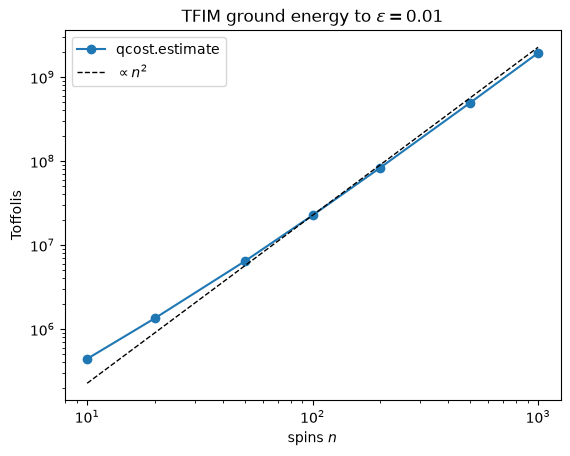

In [7]:
ns = [10, 20, 50, 100, 200, 500, 1000]
tof = [qcost.estimate(qcost.tfim(n), eps=0.01)["Toffolis"] for n in ns]
plt.loglog(ns, tof, "o-", label="qcost.estimate")
plt.loglog(ns, tof[3] * (np.array(ns) / 100) ** 2, "k--", lw=1, label=r"$\propto n^2$")
plt.xlabel("spins $n$")
plt.ylabel("Toffolis")
plt.legend()
plt.title(r"TFIM ground energy to $\epsilon = 0.01$");

## Exercises

1. Halve $\epsilon$ for the 100-spin chain. Which rows of the table double, which barely move, and why does the code distance change?
2. Move the Ising chain away from criticality ($h = 0.5$, $h = 2$). The cost changes, but the ground state gets easier to approximate classically. Which factor in the formula carries the change?
3. Write the 2D Ising model on a $4\times 4$ open square lattice as a `PauliSum` and estimate it. Compare with the 16-spin chain: what changes, $\lambda$ or the walk step?